# 04 Prescriptive analysis: referral prioritisation (PB5)
Group 5 PROHI: Risk Factor Prediction of Chronic Kidney Disease

User: Clinical Care Coordinator.

Question: which patients should get the limited referral slots so that the highest-risk patients are seen first?

Flow: risk scores (PB4 full model) → triage rules (shallow decision trees) → threshold analysis → OR-Tools selection for 5, 10 and 15 slots → what-if example with odds ratios → recommendation.

The dataset has one visit per patient, so "risk" means the risk of **current** CKD, not future progression.

In [1]:
GITHUB_USER = "mhoyor"

%cd /content
!rm -rf ckd-risk-app
!git clone https://github.com/{GITHUB_USER}/ckd-risk-app.git
%cd /content/ckd-risk-app
!pip install -q ortools

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix, roc_auc_score
from ortools.sat.python import cp_model
from data_prep import load_data, FEATURES
from viz import apply_style, COLORS, MUTED, TEXT, MODEL_COLORS, MODEL_STYLES, plot_readable_tree

apply_style()
os.makedirs("figures", exist_ok=True)

d = load_data()
df, raw = d["all"], d["raw"]
train, test = d["train"], d["test"]
y = df["class"]

# Cheap tests only (same list as PB4): history, urine dipstick, blood pressure and age
CHEAP = ["age", "bp", "bp limit", "sg", "al", "su", "htn", "dm", "cad", "appet", "pe"]
NAMES = {"hemo": "Haemoglobin", "sg": "Urine specific gravity", "al": "Urine albumin",
         "htn": "Hypertension", "dm": "Diabetes", "pcv": "Packed cell volume",
         "rbcc": "Red blood cell count", "sod": "Sodium", "bu": "Blood urea", "sc": "Serum creatinine",
         "bgr": "Random blood glucose"}

def sens_spec(y_true, flagged):
    tn, fp, fn, tp = confusion_matrix(y_true, flagged, labels=[0, 1]).ravel()
    return tp / (tp + fn), tn / (tn + fp)

print(len(df), "patients:", int(y.sum()), "CKD and", int((1 - y).sum()), "non-CKD")

200 patients: 128 CKD and 72 non-CKD


## Step 1: Risk score for every patient
The risk score is the PB4 **full model** (logistic regression on all 25 routine tests, standardised). To score all 200 patients fairly, each patient is scored by a model that did not see them (5-fold cross-validation). Expected: ROC-AUC close to 1.000, because the two groups are very easy to separate in this dataset.

In [3]:
full_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
risk = pd.Series(cross_val_predict(full_model, df[FEATURES], y, cv=cv5, method="predict_proba")[:, 1],
                 index=df.index, name="risk")

print("ROC-AUC of the risk score:", round(roc_auc_score(y, risk), 3))
scores = pd.DataFrame({"risk": risk.round(3), "stage": df["stage"], "class": y})
scores.sort_values("risk", ascending=False).head(10)

ROC-AUC of the risk score: 0.999


,risk,stage,class
2,1.0,s1,1
71,1.0,s4,1
68,1.0,s5,1
50,1.0,s4,1
65,1.0,s5,1
31,1.0,s4,1
23,1.0,s5,1
9,1.0,s3,1
56,1.0,s5,1
57,1.0,s4,1


## Step 2: Simple triage rules (decision trees, depth 2 and 3)
A shallow tree gives rules a nurse could apply by hand. Trees are trained on the 160 training patients and judged once on the 40 test patients. Sensitivity = share of CKD patients caught, specificity = share of non-CKD patients correctly left alone. Note that the tree and the risk score do not have to agree, because the tree only uses the few tests it splits on.

In [4]:
trees, rows = {}, []
for depth in (2, 3):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42).fit(train[FEATURES], train["class"])
    se, sp = sens_spec(test["class"], tree.predict(test[FEATURES]))
    trees[depth] = tree
    rows.append({"Tree depth": depth, "Sensitivity (test)": round(se, 3), "Specificity (test)": round(sp, 3)})
pd.DataFrame(rows).set_index("Tree depth")

,Sensitivity (test),Specificity (test)
Tree depth,,
2,0.846,1.0
3,0.923,1.0


In [5]:
for depth, tree in trees.items():
    print(f"If-then rules, depth {depth}:")
    print(export_text(tree, feature_names=FEATURES))

If-then rules, depth 2:
|--- hemo <= 5.50
|   |--- pcv <= 6.50
|   |   |--- class: 1
|   |--- pcv >  6.50
|   |   |--- class: 0
|--- hemo >  5.50
|   |--- al <= 0.50
|   |   |--- class: 0
|   |--- al >  0.50
|   |   |--- class: 1

If-then rules, depth 3:
|--- hemo <= 5.50
|   |--- pcv <= 6.50
|   |   |--- sod <= 5.50
|   |   |   |--- class: 1
|   |   |--- sod >  5.50
|   |   |   |--- class: 0
|   |--- pcv >  6.50
|   |   |--- class: 0
|--- hemo >  5.50
|   |--- sg <= 2.50
|   |   |--- class: 1
|   |--- sg >  2.50
|   |   |--- su <= 0.50
|   |   |   |--- class: 0
|   |   |--- su >  0.50
|   |   |   |--- class: 1



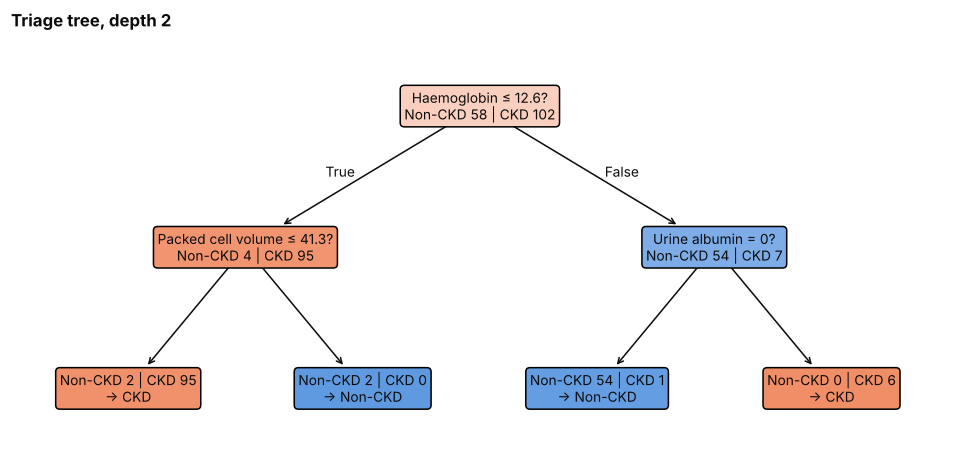

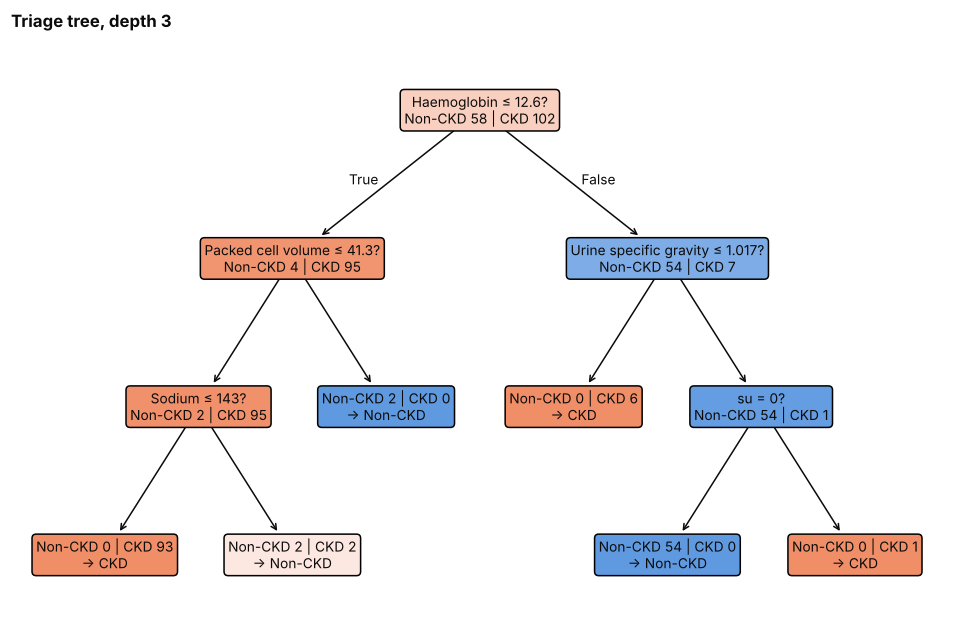

In [6]:
for depth, tree in trees.items():
    fig, ax = plt.subplots(figsize=(11, 5 if depth == 2 else 7))
    plot_readable_tree(ax, tree, FEATURES, raw=raw, names=NAMES)
    ax.set_title(f"Triage tree, depth {depth}")
    fig.savefig(f"figures/presc_tree_depth{depth}.png")
    plt.show()

## Step 3: Threshold analysis
A patient is flagged as high risk when risk ≥ threshold. A low threshold flags almost everyone (few misses, many false alarms); a high threshold flags only the surest cases. Missing a CKD patient is the costly error, so we require **sensitivity of at least 95%** and then take the highest threshold that still meets it (fewest false alarms).

In [7]:
rows = []
for t in np.round(np.arange(0.1, 0.91, 0.05), 2):
    flagged = (risk >= t).astype(int)
    se, sp = sens_spec(y, flagged)
    rows.append({"Threshold": t, "Sensitivity": round(se, 3), "Specificity": round(sp, 3),
                 "Patients flagged": int(flagged.sum())})
thr_table = pd.DataFrame(rows).set_index("Threshold")
CHOSEN = thr_table[thr_table["Sensitivity"] >= 0.95].index.max()
print("Chosen threshold:", CHOSEN)
thr_table

Chosen threshold: 0.8


,Sensitivity,Specificity,Patients flagged
Threshold,,,
0.10,1.000,0.875,137
0.15,1.000,0.903,135
0.20,1.000,0.958,131
0.25,1.000,0.972,130
0.30,0.992,0.972,129
0.35,0.984,0.972,128
0.40,0.984,0.986,127
0.45,0.977,0.986,126
0.50,0.977,0.986,126


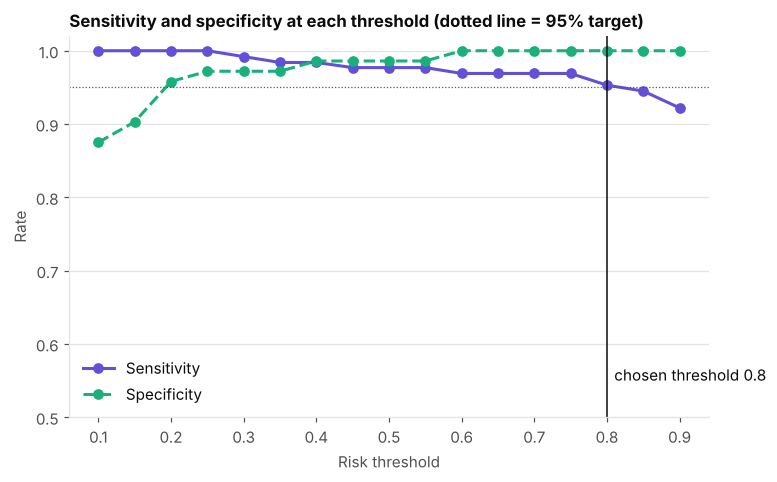

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(thr_table.index, thr_table["Sensitivity"], MODEL_STYLES["Full model"], marker="o",
        color=MODEL_COLORS["Full model"], linewidth=2, label="Sensitivity")
ax.plot(thr_table.index, thr_table["Specificity"], MODEL_STYLES["Cheap-test model"], marker="o",
        color=MODEL_COLORS["Cheap-test model"], linewidth=2, label="Specificity")
ax.axhline(0.95, color=MUTED, linewidth=0.8, linestyle=":")
ax.axvline(CHOSEN, color=TEXT, linewidth=1)
ax.text(CHOSEN + 0.01, 0.55, f"chosen threshold {CHOSEN}", color=TEXT)
ax.set_xlabel("Risk threshold")
ax.set_ylabel("Rate")
ax.set_ylim(0.5, 1.02)
ax.set_title("Sensitivity and specificity at each threshold (dotted line = 95% target)")
ax.legend(loc="lower left")
fig.savefig("figures/presc_threshold.png")
plt.show()

The same threshold analysis for the PB4 **cheap-test model** (11 cheap tests, no blood tests), to see whether it can also meet the 95% target.

In [9]:
cheap_risk = pd.Series(cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                                         df[CHEAP], y, cv=cv5, method="predict_proba")[:, 1], index=df.index)
rows = []
for name, r in {"Full model": risk, "Cheap-test model": cheap_risk}.items():
    for t in (0.5, CHOSEN):
        se, sp = sens_spec(y, (r >= t).astype(int))
        rows.append({"Model": name, "Threshold": t, "Sensitivity": round(se, 3), "Specificity": round(sp, 3)})
pd.DataFrame(rows).set_index(["Model", "Threshold"])

Sensitivity  Specificity
Model            Threshold                          
Full model       0.5              0.977        0.986
                 0.8              0.953        1.000
Cheap-test model 0.5              0.953        1.000
                 0.8              0.898        1.000

## Step 4: OR-Tools: who gets the N slots?
The model has one yes/no variable per patient. It maximises the total risk of the referred patients, subject to: at most N patients referred, and only patients with risk ≥ the chosen threshold are eligible. Many CKD patients have a risk of about 1.0, so the top N is partly a tie; ties are broken towards the more advanced stage.

We also run a variant with a rule the care team can change: at least half of the slots go to **early-stage** patients (stage 2–3), where referral can still slow progression. This 50% share is our assumption (`EARLY_SHARE`; set it to 0 to switch the rule off). Stage is not a model input; it is only used here as a rule.

In [10]:
stage = df["stage"].str.extract(r"(\d)")[0].astype(int)
early = stage.isin([2, 3])
EARLY_SHARE = 0.5

def choose_patients(n_slots, min_early=0):
    model = cp_model.CpModel()
    pick = {i: model.NewBoolVar(f"pick_{i}") for i in df.index}
    for i in df.index:
        if risk[i] < CHOSEN:
            model.Add(pick[i] == 0)                       # below the threshold: not eligible
    model.Add(sum(pick.values()) <= n_slots)              # limited slots
    if min_early:
        model.Add(sum(pick[i] for i in df.index if early[i]) >= min_early)
    # maximise total risk (in 1/10000 units), small bonus for later stage to break ties
    model.Maximize(sum((int(round(risk[i] * 10000)) * 10 + int(stage[i])) * pick[i] for i in df.index))
    solver = cp_model.CpSolver()
    status = solver.Solve(model)
    assert status in (cp_model.OPTIMAL, cp_model.FEASIBLE)
    return [i for i in df.index if solver.Value(pick[i])]

selected, rows = {}, []
for n_slots in (5, 10, 15):
    for rule, min_early in (("Highest risk only", 0), ("At least 50% early stage", int(np.ceil(n_slots * EARLY_SHARE)))):
        ids = choose_patients(n_slots, min_early)
        selected[(n_slots, rule)] = ids
        rows.append({"Slots": n_slots, "Rule": rule, "Total risk": round(risk[ids].sum(), 2),
                     "Mean risk": round(risk[ids].mean(), 3), "Early-stage patients": int(early[ids].sum()),
                     "True CKD": int(y[ids].sum())})
pd.DataFrame(rows).set_index(["Slots", "Rule"])

Total risk  Mean risk  Early-stage patients  \
Slots Rule                                                                    
5     Highest risk only                5.0        1.0                     0   
      At least 50% early stage         5.0        1.0                     3   
10    Highest risk only               10.0        1.0                     0   
      At least 50% early stage        10.0        1.0                     5   
15    Highest risk only               15.0        1.0                     0   
      At least 50% early stage        15.0        1.0                     8   

                                True CKD  
Slots Rule                                
5     Highest risk only                5  
      At least 50% early stage         5  
10    Highest risk only               10  
      At least 50% early stage        10  
15    Highest risk only               15  
      At least 50% early stage        15

The selected patients for each number of slots (row number in the dataset, risk, stage).

In [11]:
for (n_slots, rule), ids in selected.items():
    print(f"{n_slots} slots, {rule}:")
    print(scores.loc[ids].sort_values(["risk", "stage"], ascending=False).to_string())
    print()

5 slots, Highest risk only:
     risk stage  class
163   1.0    s5      1
175   1.0    s5      1
178   1.0    s5      1
192   1.0    s5      1
194   1.0    s5      1

5 slots, At least 50% early stage:
     risk stage  class
175   1.0    s5      1
178   1.0    s5      1
9     1.0    s3      1
41    1.0    s3      1
83    1.0    s3      1

10 slots, Highest risk only:
     risk stage  class
111   1.0    s5      1
113   1.0    s5      1
140   1.0    s5      1
141   1.0    s5      1
146   1.0    s5      1
163   1.0    s5      1
175   1.0    s5      1
178   1.0    s5      1
192   1.0    s5      1
194   1.0    s5      1

10 slots, At least 50% early stage:
     risk stage  class
113   1.0    s5      1
140   1.0    s5      1
141   1.0    s5      1
146   1.0    s5      1
163   1.0    s5      1
9     1.0    s3      1
41    1.0    s3      1
83    1.0    s3      1
112   1.0    s3      1
161   1.0    s3      1

15 slots, Highest risk only:
     risk stage  class
87    1.0    s5      1
92    1.0  

## Step 5: What-if example with odds ratios
For logistic regression, `exp(coefficient)` is the **odds ratio**: how many times the odds of CKD are multiplied when a test goes up by one unit (for hypertension `htn` and diabetes `dm`, from 0 = no to 1 = yes). For this step the model is fitted without standardising so that the odds ratios are per one unit. These are associations in cross-sectional data, not proof of cause.

In [12]:
lr = LogisticRegression(max_iter=5000).fit(df[FEATURES], y)
odds_ratios = pd.Series(np.exp(lr.coef_[0]), index=FEATURES, name="Odds ratio")
odds_ratios[["htn", "dm"]].round(2)

htn    2.03
dm     1.54
Name: Odds ratio, dtype: float64

What-if: take the patient **without hypertension** whose risk is closest to the chosen threshold (the patient most affected by a change) and switch `htn` from 0 to 1. The ratio of the new odds to the old odds should equal the odds ratio of `htn`.

In [13]:
no_htn = df.index[df["htn"] == 0]
pid = (risk[no_htn] - CHOSEN).abs().idxmin()

before = df.loc[[pid], FEATURES]
after = before.copy()
after["htn"] = 1
p0, p1 = lr.predict_proba(before)[0, 1], lr.predict_proba(after)[0, 1]
odds = lambda p: p / (1 - p)

pd.DataFrame({"Hypertension": [0, 1], "Risk": [round(p0, 3), round(p1, 3)],
              "Odds": [round(odds(p0), 3), round(odds(p1), 3)]}, index=["Before", "After"]).T

,Before,After
Hypertension,0.000,1.000
Risk,0.852,0.921
Odds,5.756,11.668


In [14]:
print(f"Odds after / odds before = {odds(p1) / odds(p0):.2f}")
print(f"exp(coefficient of htn)  = {odds_ratios['htn']:.2f}")

Odds after / odds before = 2.03
exp(coefficient of htn)  = 2.03


## Step 6: Answers to the Care Coordinator's question (copy into the PB5 Trello card and the report)
1. **Rank patients by the risk score and refer from the top.** The PB4 full model gives a risk for every patient (ROC-AUC 0.999 in cross-validation). Flag a patient as high risk at a risk of **0.80 or above**: this is the highest threshold that still catches at least 95% of CKD patients (sensitivity 0.953, specificity 1.000, 122 of 200 patients flagged).
2. **Simple triage rules work for a quick check but miss more.** The depth-3 tree (haemoglobin → packed cell volume → sodium on the anaemic branch; urine specific gravity → urine sugar otherwise) caught 92% of CKD patients in the test set with no false alarms; the depth-2 tree (haemoglobin, packed cell volume, urine albumin) caught 85%. Both are below the 95% target, so the risk score is used for the actual decision and the tree is a backup rule.
3. **With 5, 10 or 15 slots, OR-Tools refers only patients at or above the threshold, highest risk first.** All 5, 10 and 15 selected patients are true CKD (total risk 5.0, 10.0 and 15.0). Many patients share a risk of about 1.0, so the order within them is a tie, broken towards the more advanced stage. If the team wants at least half of the slots for early-stage patients (stage 2–3), the same total risk is kept with 3, 5 and 8 early-stage patients. The 50% share is our assumption and should be confirmed with the care team.
4. **Hypertension and diabetes raise the odds of CKD.** Odds ratios: hypertension 2.03 and diabetes 1.54. In the what-if example, a patient with risk 0.852 and no hypertension goes to 0.921 if hypertension is present; the odds double (ratio 2.03, equal to the odds ratio), so patients with these conditions deserve a closer look.
5. **Cheap tests alone are not enough at this threshold.** The cheap-test model (no blood tests) reaches sensitivity 0.953 at threshold 0.5 but only 0.898 at 0.80, so with the strict 0.80 cut-off the full model is needed; the cheap-test model fits a first screening step with a lower threshold.
6. **Limits:** the data are one visit per patient, so these are associations, not causes, and the score shows current CKD, not future progression. The groups are almost perfectly separable (AUC about 1), so trust the ranking more than the exact probabilities. Only 200 patients from one hospital were used; the tool supports the clinician's judgement and does not replace it.


## Step 7: Recommendation for the Care Coordinator (plain English)
1. **Rank all patients by their kidney-disease risk score and give the referral slots from the top of the list down.**
2. **Draw the line at 0.80.** Patients with a score of 0.80 or higher are "high risk". In our data this line finds about 95 of every 100 patients who really have kidney disease and wrongly flags none of the healthy patients.
3. **Fill the slots from the lists in Step 4.** There is one list each for 5, 10 and 15 slots. Many patients are tied at the very top, so if the team wants, keep at least half of the slots for patients in the early stages, where referral can still slow the disease. This share is our suggestion; the care team decides it.
4. **If no score is available,** the short checklist in the Step 2 chart finds about 9 in 10 patients. Use it only as a backup, because it misses more people than the score.
5. **Look more closely at patients with high blood pressure or diabetes.** They are clearly more likely to have kidney disease (about double for high blood pressure).
6. **Be aware of the limits.** This is based on only 200 patients from one hospital. It shows who probably has kidney disease now, not who will get worse. It shows patterns, not proof of cause. It helps you decide, but the clinician makes the final call, and it should be checked on more patients before real use.

## Step 8: Download all figures

In [15]:
import shutil
from google.colab import files

shutil.make_archive("prescriptive_figures", "zip", "figures")
files.download("prescriptive_figures.zip")